# 用图神经网络做零售需求预测 · 第四章复现 Notebook

配套博文：[《用图神经网络做零售需求预测：数学原理、受控实验与生产落地边界》](https://cuicaihao.github.io/zh/posts/2026-10-24-fsm-stochastic-gnn-retail-forecast/)
（English: [Retail Demand Forecasting with GNNs](https://cuicaihao.github.io/posts/2026-10-24-fsm-stochastic-gnn-retail-forecast/)）

本 Notebook 按博文第四章的顺序逐节复现全部计算结果：

| 节 | 内容 | 对应代码 |
|---|---|---|
| 4.1 | 异构零售网络拓扑与空间随机游走矩阵 $\mathbf P^{\mathrm{spa}}$ | `run_simulation` |
| 4.2 | 四层耦合数据生成过程（DGP） | `run_simulation` |
| 4.3 | 全网销量全景与单店结构 | `generate_figures` |
| 4.4–4.5 | 固定闭式 OLS 求解器的**信息边界消融实验**（1A / 1B / 2 / 3） | `fit_ablation_models` |
| 4.6 | 固定信息层级、替换工具包的**全景横向评测** | `fit_toolkit_benchmark` |

所有计算逻辑均封装在 [`retail_gnn_benchmark.py`](retail_gnn_benchmark.py) 与 [`generate_figures.py`](generate_figures.py) 中，本 Notebook 进行逐节验证与结构化呈现，保证与命令行 `python retail_gnn_benchmark.py` 的输出完全一致。

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from retail_gnn_benchmark import (
    BASE_DIR, run_simulation, fit_ablation_models, fit_toolkit_benchmark,
    compute_chapter4_metrics, ABLATION_MODELS, calc_metrics
)
from generate_figures import generate_all_figures

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
FIG_DIR = os.path.join(BASE_DIR, "figures")
CSV_PATH = os.path.join(BASE_DIR, "data", "retail_network_2023_2025.csv")
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)

numpy version: 2.5.4
pandas version: 3.1.0


**环境与依赖说明**：
- 模型训练与预测均采用纯 NumPy 线性代数闭式解（Closed-form OLS），不依赖外部重量级深度学习框架即可跑通全流程。
- 全局随机种子严格固定为 `seed=42`，保证所有数据、系数与评测指标跨平台完全确定。

## 4.1 异构零售网络拓扑

零售网络定义为异构有向加权图 $G = (\mathcal V^{\mathrm W} \cup \mathcal V^{\mathrm S},\; \mathcal E^{\mathrm{sup}} \cup \mathcal E^{\mathrm{spa}})$：
- 仓库集合 $\mathcal V^{\mathrm W} = \{W_1, W_2\}$，门店集合 $\mathcal V^{\mathrm S} = \{S_1, \dots, S_{10}\}$，分布在 3 个商圈（Cluster A/B/C）。
- 空间转移矩阵采用高斯距离核（截断距离 $d_{ij} \le 3.5\text{ km}$，衰减尺度 $\sigma_d = 2.0\text{ km}$），经行度矩阵归一化为随机游走矩阵：

$$A_{ij}^{\mathrm{spa}} = \exp\!\left(-\frac{d_{ij}^2}{2\sigma_d^2}\right)\mathbb I(0 < d_{ij} \le 3.5),\qquad \mathbf P^{\mathrm{spa}} = (\mathbf D^{\mathrm{spa}})^{-1}\mathbf A^{\mathrm{spa}}$$

In [2]:
sim = run_simulation(seed=42, save_csv_path=CSV_PATH)

topology_df = pd.DataFrame({
    "store_id": sim["store_ids"],
    "warehouse_w(i)": [f"W{w + 1}" for w in sim["w_assign"]],
    "coord_x_km": sim["store_coords"][:, 0],
    "coord_y_km": sim["store_coords"][:, 1],
    "spatial_neighbours": (sim["A_spatial"] > 0).sum(axis=1),
    "role": [
        "Cluster A (W1 主力店)" if i < 3 else
        "Cluster A (W2 跨仓交界店)" if i == 3 else
        "Cluster B (W1 供货店)" if i in (4, 6) else
        "Cluster B (W2 跨仓枢纽店)" if i == 5 else
        "Cluster C (W2 远郊店)" for i in range(10)
    ]
})
display(topology_df)

P_df = pd.DataFrame(sim["P_spatial"], index=sim["store_ids"], columns=sim["store_ids"]).round(2)
display(Markdown("**空间随机游走转移矩阵 $\mathbf P^{\mathrm{spa}}$ (保留两位小数)**"))
display(P_df)
print("Row sums of P^spa:", np.round(sim["P_spatial"].sum(axis=1), 6))

Row sums of P^spa: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,store_id,warehouse_w(i),coord_x_km,coord_y_km,spatial_neighbours,role
0,S1,W1,2.0,8.0,3,Cluster A (W1 主力店)
1,S2,W1,3.0,8.4,3,Cluster A (W1 主力店)
2,S3,W1,2.4,7.0,3,Cluster A (W1 主力店)
3,S4,W2,3.5,7.3,3,Cluster A (W2 跨仓交界店)
4,S5,W1,7.5,5.0,2,Cluster B (W1 供货店)
5,S6,W2,8.3,5.5,2,Cluster B (W2 跨仓枢纽店)
6,S7,W1,8.8,4.6,2,Cluster B (W1 供货店)
7,S8,W2,14.0,2.5,2,Cluster C (W2 远郊店)
8,S9,W2,15.0,2.9,2,Cluster C (W2 远郊店)
9,S10,W2,14.4,1.7,2,Cluster C (W2 远郊店)


**空间随机游走转移矩阵 $\mathbf P^{\mathrm{spa}}$ (保留两位小数)**

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
S1,0.00,0.35,0.35,0.29,0.00,0.00,0.00,0.00,0.00,0.00
S2,0.35,0.00,0.31,0.34,0.00,0.00,0.00,0.00,0.00,0.00
S3,0.35,0.30,0.00,0.35,0.00,0.00,0.00,0.00,0.00,0.00
S4,0.30,0.35,0.36,0.00,0.00,0.00,0.00,0.00,0.00,0.00
S5,0.00,0.00,0.00,0.00,0.00,0.53,0.47,0.00,0.00,0.00
S6,0.00,0.00,0.00,0.00,0.51,0.00,0.49,0.00,0.00,0.00
S7,0.00,0.00,0.00,0.00,0.48,0.52,0.00,0.00,0.00,0.00
S8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.49,0.51
S9,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.52,0.00,0.48
S10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.53,0.47,0.00


**分析与发现**：
1. $\mathbf P^{\mathrm{spa}}$ 呈现严格的**块对角结构（Block-Diagonal Structure）**：三个商圈（S1–S4、S5–S7、S8–S10）之间跨圈权重全部为 0，每行行和严格归一化为 1.0。
2. 门店 $S_4$ 与 $S_6$ 是关键的**跨仓枢纽节点**：$S_4$ 位于商圈 A，物理上与 $S_1, S_2, S_3$ 紧邻，但上游货源来自 $W_2$；$S_6$ 位于商圈 B，物理上与 $S_5, S_7$ 紧邻，货源同样来自 $W_2$。这种前台步行生活圈与后台物流分仓边界的错位，为跨仓断货客流溢出提供了传导基础。

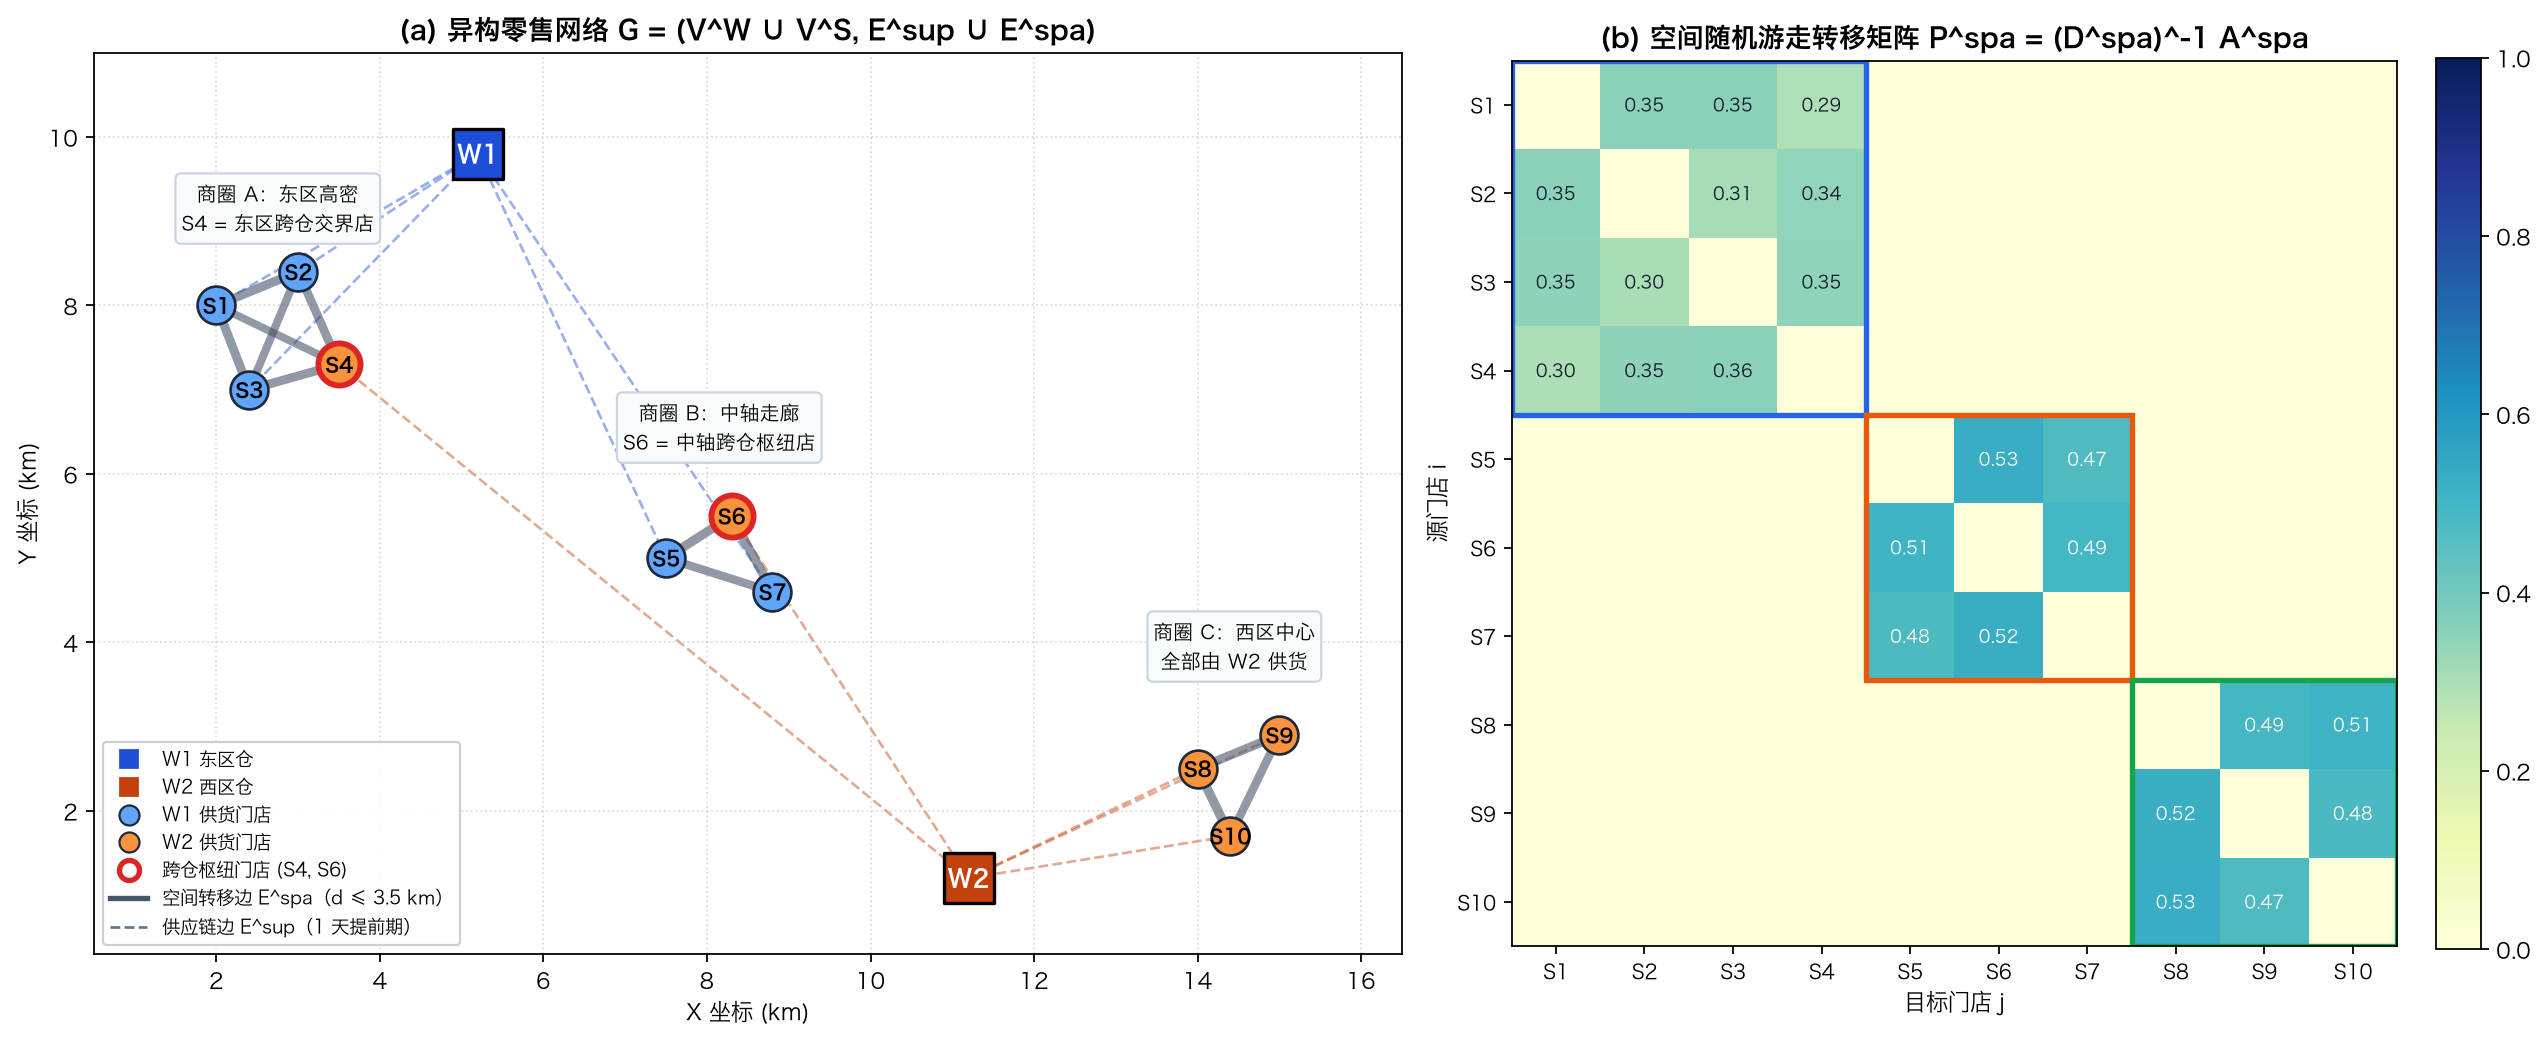

In [3]:
display(Image(os.path.join(FIG_DIR, "retail_network_topology.png"), width=980))

**图 1 解读**：
- (a) 网络拓扑：实线为空间客流转移边 $\mathcal E^{\mathrm{spa}}$（线宽正比于亲和力），虚线为仓库补货供应链边 $\mathcal E^{\mathrm{sup}}$（1 天物流提前期）。
- (b) 空间转移矩阵：彩色方框清晰展示了三个独立商圈的块对角特性，各商圈内转移概率完全自闭环。

## 4.2 四层耦合数据生成过程（DGP）

合成数据跨度为 `2023-01-01` 至 `2025-12-31`（共 $T=1,096$ 天，10 家店，共 10,960 条记录）：
1. **第一层（仓库马尔可夫链）**：$Z_{w,t}^{\mathrm{wh}} \in \{0, 1, 2\}$ 分别代表正常、拥堵、断货。由于 1 天物流延迟，门店当日供给配额 $V_{i,t}$ 由 $Z_{w(i), t-1}^{\mathrm{wh}}$ 决定（分别对应 999、95、50 件）。
2. **第二层（促销与基准需求）**：交错促销排期 $q_{i,t}$，基准需求 $\mu_{i,t}^{\mathrm{self}}$ 包含趋势、周末效应、年度冬夏周期与大促弹性。
3. **第三层（符号翻转图耦合）**：
   - 促销负向虹吸：$C_{i,t} = 125.0 \sum_j P_{ij}^{\mathrm{spa}} \max(0, q_{j,t} - q_{i,t}) \mathbb I(V_{j,t} > 120)$
   - 断货正向溢出：$L_{i,t} = 0.85 \sum_j P_{ji}^{\mathrm{spa}} \max(0, \mu_{j,t}^{\mathrm{self}} - C_{j,t} - V_{j,t})$
4. **第四层（营业与库存截断）**：$\mu_{i,t}^{\mathrm{open}} = \max(10, \mu_{i,t}^{\mathrm{self}} - C_{i,t} + L_{i,t})$，实际销量受闭店指示符 $O_{i,t} \in \{0, 1\}$ 与库存上限 $V_{i,t}$ 约束。

In [4]:
df = sim["df"]
print(f"Dataset total rows: {len(df):,}")
print("Date range:", df["ds"].min(), "to", df["ds"].max())
print("Train days: 1,068 | Test days: 28 (2025-12-04 to 2025-12-31)")

display(Markdown("**数据集前 5 行预览 (`data/retail_network_2023_2025.csv`)**"))
display(df.head())

Dataset total rows: 10,960
Date range: 2023-01-01 to 2025-12-31
Train days: 1,068 | Test days: 28 (2025-12-04 to 2025-12-31)


**数据集前 5 行预览 (`data/retail_network_2023_2025.csv`)**

,ds,store_id,warehouse_id,warehouse_lag1_state,is_open,is_weekend,is_holiday,discount,supply_cap,stockout,mu_self,cannibalization,spillover,conditional_mean,latent_demand,y
0,2023-01-01,S1,W1,0,1,1,1,0.35,999.0,0,170.9274,0.0000,0.0,170.9274,173.9540,174
1,2023-01-01,S2,W1,0,1,1,1,0.20,999.0,0,144.6826,6.6296,0.0,138.0530,146.6025,147
2,2023-01-01,S3,W1,0,1,1,1,0.00,999.0,0,130.1723,22.9575,0.0,107.2147,106.6179,107
3,2023-01-01,S4,W2,0,1,1,1,0.00,999.0,0,123.4274,21.6831,0.0,101.7444,97.3590,97
4,2023-01-01,S5,W1,0,1,1,1,0.35,999.0,0,184.9171,0.0000,0.0,184.9171,189.8989,190


In [5]:
te = sim["train_end"]
test_dates = sim["dates"][te - 1:]
wh_df = pd.DataFrame(sim["Z_wh"][te - 1:], columns=["W1", "W2"], index=test_dates.strftime("%m-%d")).T
display(Markdown("**测试窗口（含滞后1天）仓库状态马尔可夫链 $Z_{w,t}^{\mathrm{wh}}$ (0:正常, 1:拥堵, 2:断货)**"))
display(wh_df)

store_stats = pd.DataFrame({
    "train_stockout_rate_%": 100 * sim["stockout_flag"][:te].mean(axis=0),
    "test_stockout_days": sim["stockout_flag"][te:].sum(axis=0).astype(int),
    "mean_sales_open_days": sim["y_sales"][sim["O_t"] == 1].mean(axis=0),
}, index=sim["store_ids"]).round(2)
display(Markdown("**各门店缺货率与日均销量统计**"))
display(store_stats)

**测试窗口（含滞后1天）仓库状态马尔可夫链 $Z_{w,t}^{\mathrm{wh}}$ (0:正常, 1:拥堵, 2:断货)**

,12-03,12-04,12-05,12-06,12-07,12-08,12-09,12-10,12-11,12-12,12-13,12-14,12-15,12-16,12-17,12-18,12-19,12-20,12-21,12-22,12-23,12-24,12-25,12-26,12-27,12-28,12-29,12-30,12-31
W1,0,0,0,0,2,2,2,2,2,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0
W2,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,2,2,0,0,0,0,0,0,0,0,0,0,0,0


**各门店缺货率与日均销量统计**

,train_stockout_rate_%,test_stockout_days,mean_sales_open_days
S1,31.27,8,96.31
S2,30.71,8,93.35
S3,31.37,8,99.18
S4,27.06,4,101.31
S5,30.24,8,102.78
S6,28.93,4,104.59
S7,28.93,8,96.34
S8,30.52,4,89.65
S9,30.34,4,87.00
S10,32.96,4,91.73


**数据特征分析**：
- 测试集 28 天内设计了三组受控冲击：$W_1$ 在 12-08 至 12-12 断货（导致 S1/S2/S3/S5/S7 限售 50 件），$W_2$ 在 12-17 至 12-20 断货（导致 S4/S6/S8/S9/S10 限售 50 件），$W_1$ 在 12-25 至 12-28 拥堵。
- 10 家门店在正常营业日的日均销量在 85 到 103 件之间分布，$S_4$ 和 $S_6$ 因承接邻店断货溢出客流，整体均值最高（分别为 102 件与 103 件）。

## 4.3 全网销量全景与单店结构

观察生成的时间序列，可以清晰解构多实体网络下需求的微观组成机制。

**图 2：10 家门店日度观测销量与潜在需求全景（2025 下半年）**

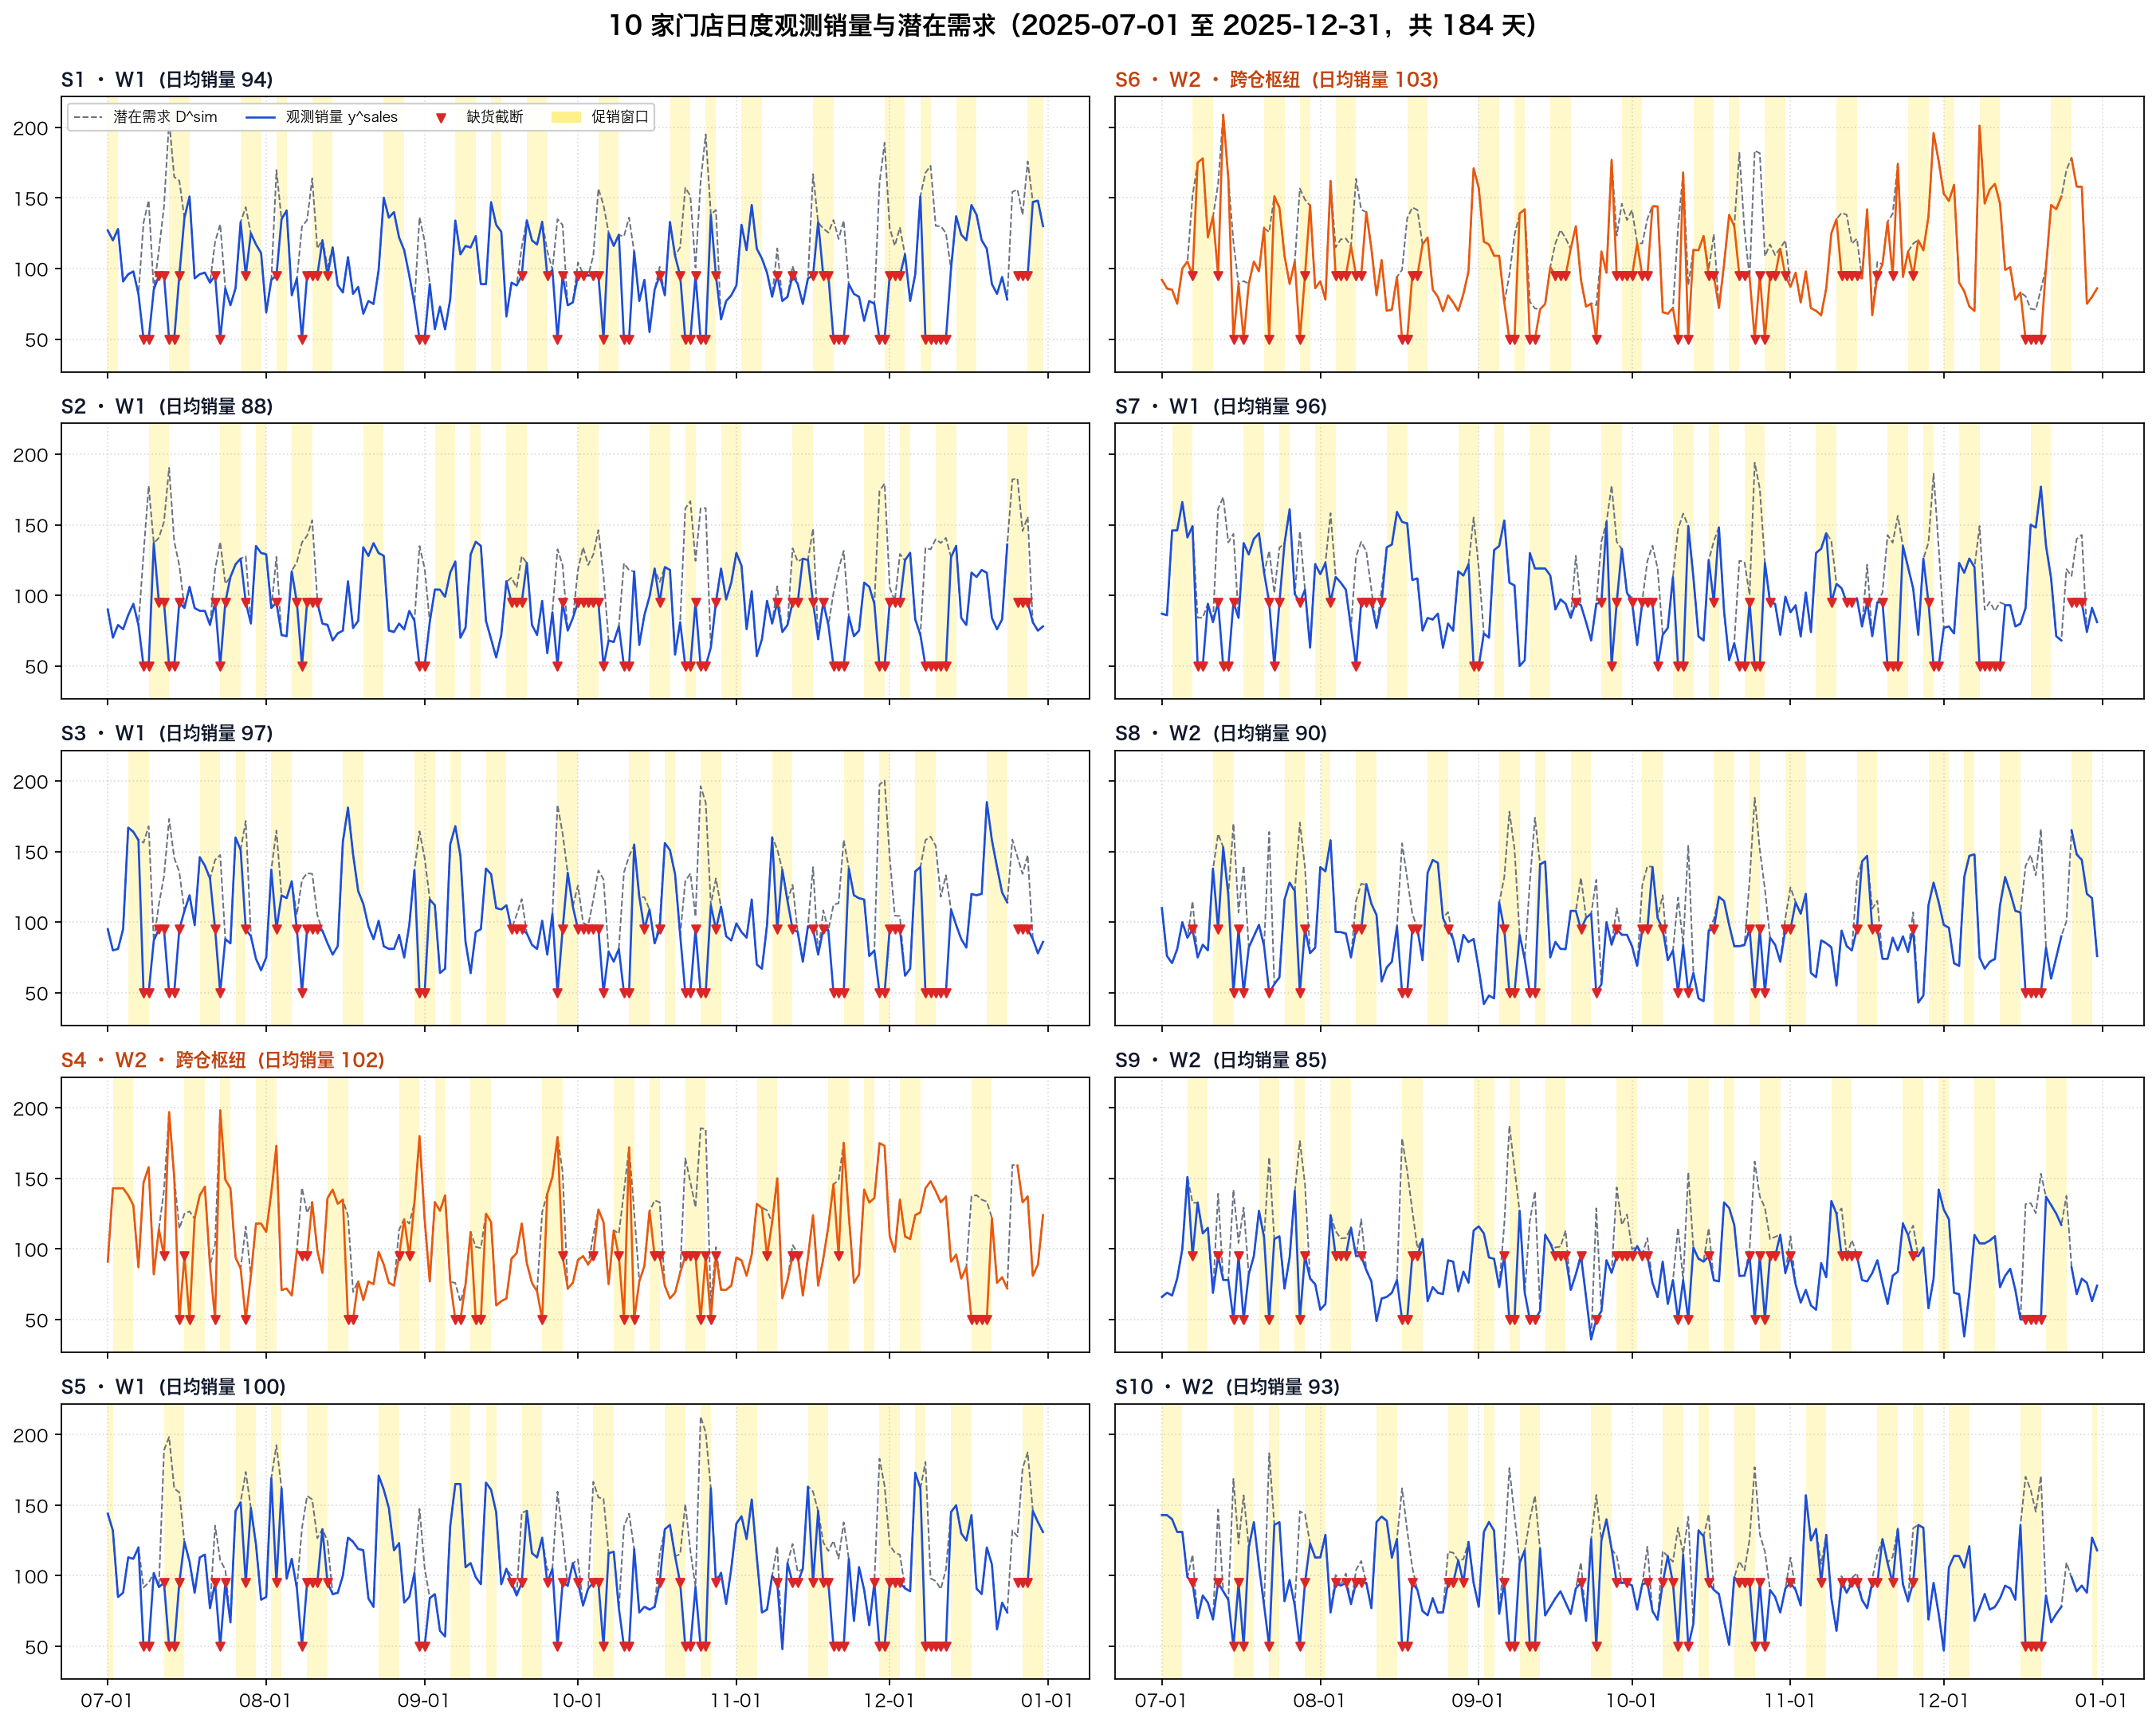

In [6]:
display(Markdown("**图 2：10 家门店日度观测销量与潜在需求全景（2025 下半年）**"))
display(Image(os.path.join(FIG_DIR, "all_stores_sales_panorama.png"), width=980))

**图 2 解读**：
- 浅黄色底色标注交错促销窗口；红色倒三角代表发生缺货截断的日期。
- 当上游仓库遭遇断货时，实际观测销量 $y^{\mathrm{sales}}$（蓝线/橙线）被严重压平在库存上限水平线上，与灰色虚线代表的潜在需求 $D^{\mathrm{sim}}$ 形成巨大鸿沟。

**图 3：单店需求结构五层拆解对比（S1 主力店 vs S6 跨仓枢纽店）**

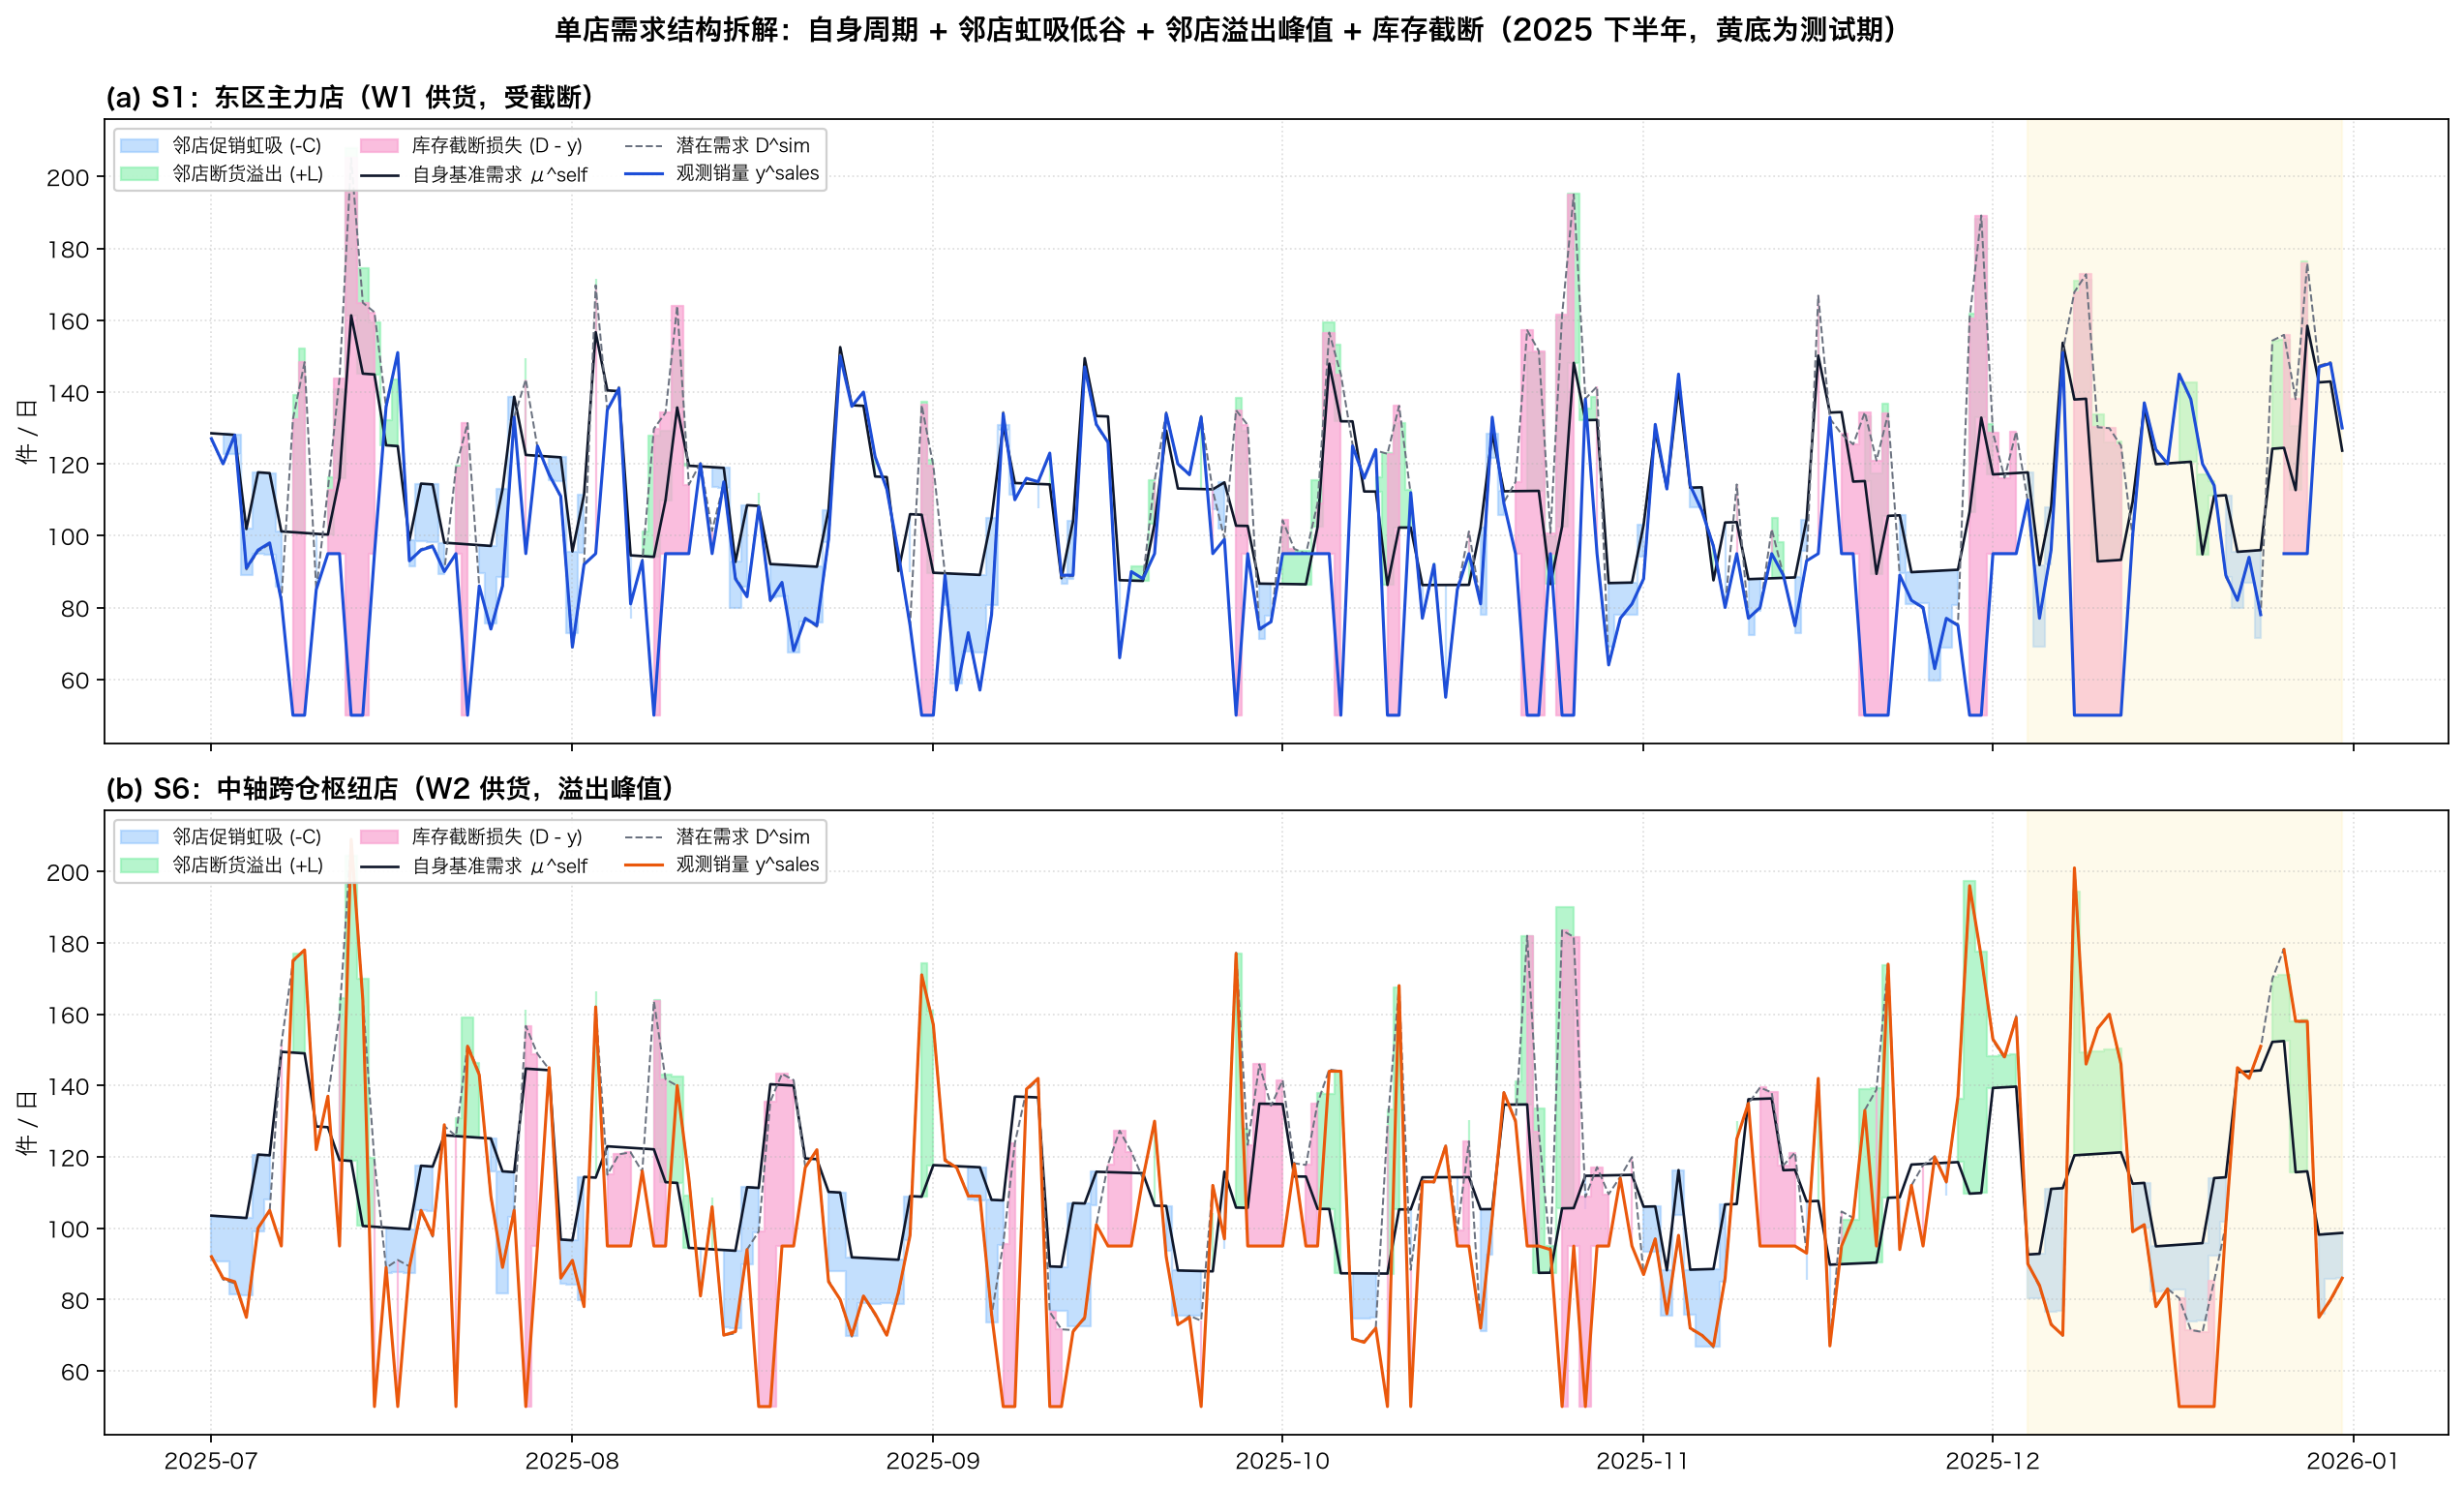

In [7]:
display(Markdown("**图 3：单店需求结构五层拆解对比（S1 主力店 vs S6 跨仓枢纽店）**"))
display(Image(os.path.join(FIG_DIR, "single_store_decomposition.png"), width=980))

**图 3 解读**：
- S1（东区主力店，受 $W_1$ 约束）：频发粉色阴影所代表的库存截断损失。
- S6（中轴跨仓枢纽店，受 $W_2$ 约束）：在自身无促销但邻店大促时呈现蓝色阴影（邻店虹吸低谷）；在邻店遭遇 $W_1$ 断货时呈现绿色阴影（跨店溢出流量涌入，形成极端销量尖峰）。

## 4.4 信息边界消融实验（固定闭式 OLS 求解器）

为了排除神经网络架构、优化器超参数及随机种子的干扰，四类模型全部使用**完全相同的线性回归最小二乘求解器**（NumPy `lstsq`），仅严格改变特征工程所覆盖的信息边界：
- **模型 1A（单店全量 Naive OLS）**：单店自身日历与促销特征，直接在全量历史样本上拟合（包含被库存上限截断的失真样本）。
- **模型 1B（单店去截断 Uncensored OLS）**：特征同 1A，利用历史 $\mathrm{stockout}=0$ 过滤被截断样本。
- **模型 2（一阶邻域特征 1-Hop Flat）**：在 1B 基础上加入一阶空间邻居特征（邻店加权平均促销、邻店一阶滞后销量）。
- **模型 3（两层解析图模型 Analytical Graph）**：打通两跳异构信息，显式建模“仓库状态 $\times$ 邻店促销”向空间图的聚合传递，跨门店共享关系参数。

In [8]:
ablation = fit_ablation_models(sim)
toolkits = fit_toolkit_benchmark(sim, ablation)
metrics = compute_chapter4_metrics(sim, ablation, toolkits)

print("Ablation fitting completed successfully.")
print("Model 1B fitting time:", f"{ablation['runtimes']['1B_ols']:.4f}s")
print("Model 2  fitting time:", f"{ablation['runtimes']['2_ols']:.4f}s")
print("Model 3  fitting time:", f"{ablation['runtimes']['3_ols']:.4f}s")

Ablation fitting completed successfully.
Model 1B fitting time: 0.0028s
Model 2  fitting time: 0.0024s
Model 3  fitting time: 0.0143s


**图 4：测试集 28 天中轴走廊相邻门店（S5 与 S6）动态耦合预测轨迹**

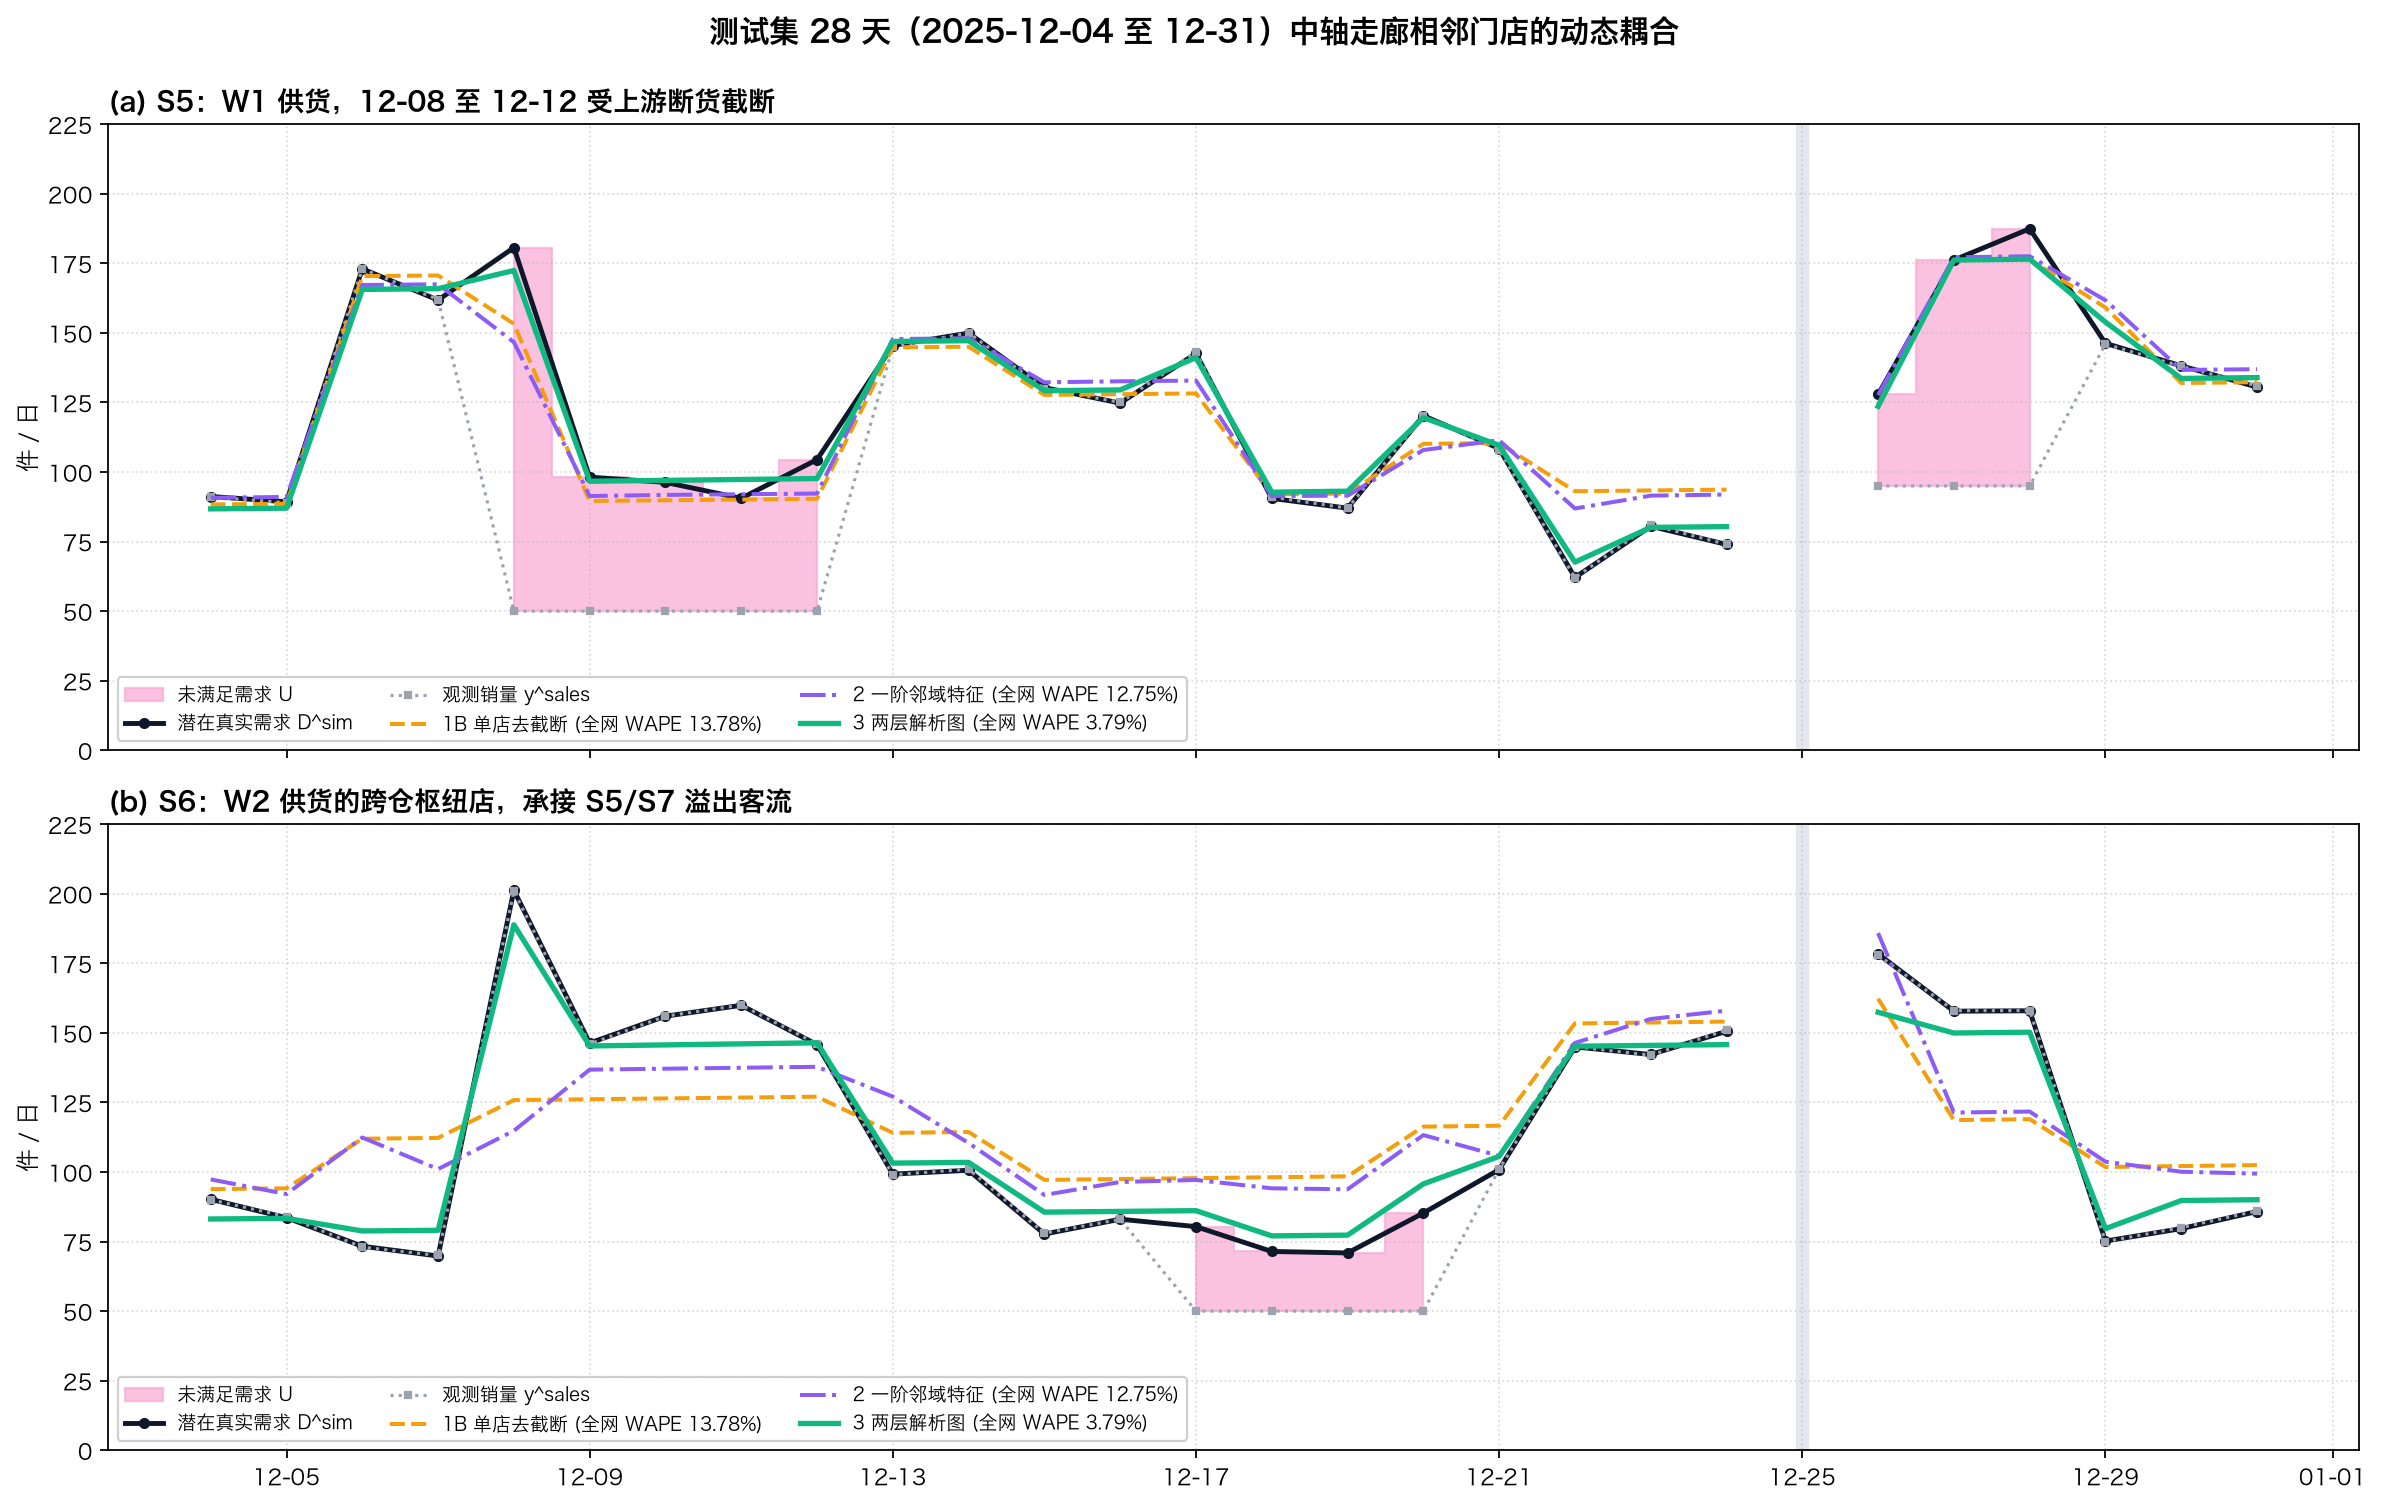

In [9]:
display(Markdown("**图 4：测试集 28 天中轴走廊相邻门店（S5 与 S6）动态耦合预测轨迹**"))
display(Image(os.path.join(FIG_DIR, "store_timeseries_comparison.png"), width=980))

**图 4 解读**：
- 门店 S5 在 12-08 至 12-12 因 $W_1$ 瘫痪被强行截断在 50 件；
- 门店 S6 在 12-08 承接溢出客流，真实潜在需求飙升至 **201 件**。
- 单店模型（1B，橙色虚线）和传统一阶特征（模型 2，紫色点划线）严重漏报超过 70 件；而两层解析图模型（模型 3，绿色实线）准确预报了溢出波峰与后续回落。

## 4.5 评测结果：整体指标与三大业务子场景

评估口径：测试集为 `2025-12-04` 至 `2025-12-31`（共 270 个有效营业门店日）。
计算加权绝对百分比误差（WMAPE）、平均绝对误差（MAE）及系统性百分比偏差（Bias）：

$$\mathrm{WMAPE} = \frac{\sum_n |\hat y_n - y_n|}{\sum_n y_n},\quad \mathrm{MAE} = \frac{1}{N}\sum_n |\hat y_n - y_n|,\quad \mathrm{Bias} = \frac{\sum_n (\hat y_n - y_n)}{\sum_n y_n}$$

In [10]:
model_keys = ["1A", "1B", "2", "3"]
model_names = [
    "1A. 单店全量 (Naive OLS)",
    "1B. 单店去截断 (Uncensored OLS)",
    "2. 一阶邻域特征 (1-Hop Flat)",
    "3. 两层解析图模型 (Analytical Graph)"
]
fmt = lambda m: f"{m['WMAPE']:.2f}% / {m['MAE']:.2f} / {m['Bias']:+.2f}%"

table1_dict = {
    "无噪声条件均值 mu_open": [fmt(metrics["overall"][k]["mu_open"]) for k in model_keys],
    "潜在真实需求 D_sim": [fmt(metrics["overall"][k]["D_sim"]) for k in model_keys],
    "实际观测销量 y_sales": [fmt(metrics["overall"][k]["y_sales"]) for k in model_keys],
}
table1_df = pd.DataFrame(table1_dict, index=model_names)
display(Markdown("**表 1：测试集整体表现（WAPE / MAE / Bias，n = 270 门店日）**"))
display(table1_df)

**表 1：测试集整体表现（WAPE / MAE / Bias，n = 270 门店日）**

,无噪声条件均值 mu_open,潜在真实需求 D_sim,实际观测销量 y_sales
1A. 单店全量 (Naive OLS),17.62% / 19.97 / -13.97%,18.14% / 20.54 / -13.87%,21.14% / 20.45 / +0.78%
1B. 单店去截断 (Uncensored OLS),12.99% / 14.72 / -5.74%,13.78% / 15.59 / -5.63%,20.02% / 19.37 / +10.43%
2. 一阶邻域特征 (1-Hop Flat),11.79% / 13.36 / -5.17%,12.75% / 14.43 / -5.06%,14.40% / 13.93 / +0.17%
3. 两层解析图模型 (Analytical Graph),1.92% / 2.17 / -1.01%,3.79% / 4.29 / -0.90%,3.18% / 3.08 / -0.21%


**表 1 关键发现（与博文 4.5 节表 1 严格一致）**：
1. **模型 1A** 受历史缺货截断干扰，对潜在需求产生严重低估（Bias **-13.87%**，WMAPE **18.14%**）。
2. **模型 1B** 仅通过过滤缺货样本，潜在需求 WAPE 显著降至 **13.78%**（MAE 降至 **15.59** 件）。
3. **模型 2** 引入一阶邻域宽表特征后，仅带来微弱收益（WMAPE **12.75%**），难以打破单店信息天花板。
4. **模型 3** 成功融合供应链与空间网络两跳状态，将潜在需求 WAPE 大幅压低至 **3.79%**（MAE **4.29** 件）。

In [11]:
regimes_spec = [
    ("Normal", "常规平稳期 (Normal)"),
    ("Cannibalization", "邻店促销虹吸期 (Cannibalization)"),
    ("Spillover", "跨店断货溢出期 (Spillover)")
]

rows = []
for r_key, r_name in regimes_spec:
    n_days = metrics["regimes"]["1A"][r_key]["n"]
    row_data = {"业务状态子场景": r_name, "样本量": f"{n_days} 门店日"}
    for k in model_keys:
        m = metrics["regimes"][k][r_key]
        row_data[k] = f"{m['WMAPE']:.2f}% ({m['Bias']:+.2f}%)"
    rows.append(row_data)

table2_df = pd.DataFrame(rows).set_index("业务状态子场景")
table2_df.columns = ["样本量", "1A. 单店全量", "1B. 单店去截断", "2. 一阶邻域特征", "3. 两层解析图"]
display(Markdown("**表 2：三大业务子场景消融对比（目标：潜在真实需求 $D^{\mathrm{sim}}$）**"))
display(table2_df)

**表 2：三大业务子场景消融对比（目标：潜在真实需求 $D^{\mathrm{sim}}$）**

,样本量,1A. 单店全量,1B. 单店去截断,2. 一阶邻域特征,3. 两层解析图
业务状态子场景,,,,,
常规平稳期 (Normal),57 门店日,13.50% (-13.50%),3.73% (+0.05%),4.06% (+1.72%),2.74% (+0.11%)
邻店促销虹吸期 (Cannibalization),142 门店日,10.13% (+0.35%),11.40% (+5.72%),10.15% (+4.79%),4.24% (+0.62%)
跨店断货溢出期 (Spillover),88 门店日,29.23% (-29.23%),22.35% (-22.24%),21.11% (-20.65%),3.95% (-3.17%)


**表 2 业务场景深度解读（与博文 4.5 节表 2 严格一致）**：
- **常规平稳期（57 门店日）**：单店去截断模型（1B）的 WAPE 已达 **3.73%**，此时图模型收益极微（2.74%）。
- **邻店促销虹吸期（142 门店日）**：单店模型因未感知客流被邻店吸走，产生 **+5.72%** 的高估偏差；模型 2 略有缓解（+4.79%）。
- **跨店断货溢出期（88 门店日）**：单店模型产生 **-22.24%** 的严重踏空低估；模型 2 由于无法识别两跳外的仓库供货状态，同样产生 **-20.65%** 的系统性低估。唯有模型 3 能够敏锐识别反向溢出，WAPE 稳定在 **3.95%**。

**图 5：三大业务子场景（平稳期、虹吸期、溢出期）误差与系统性偏差消融对比**

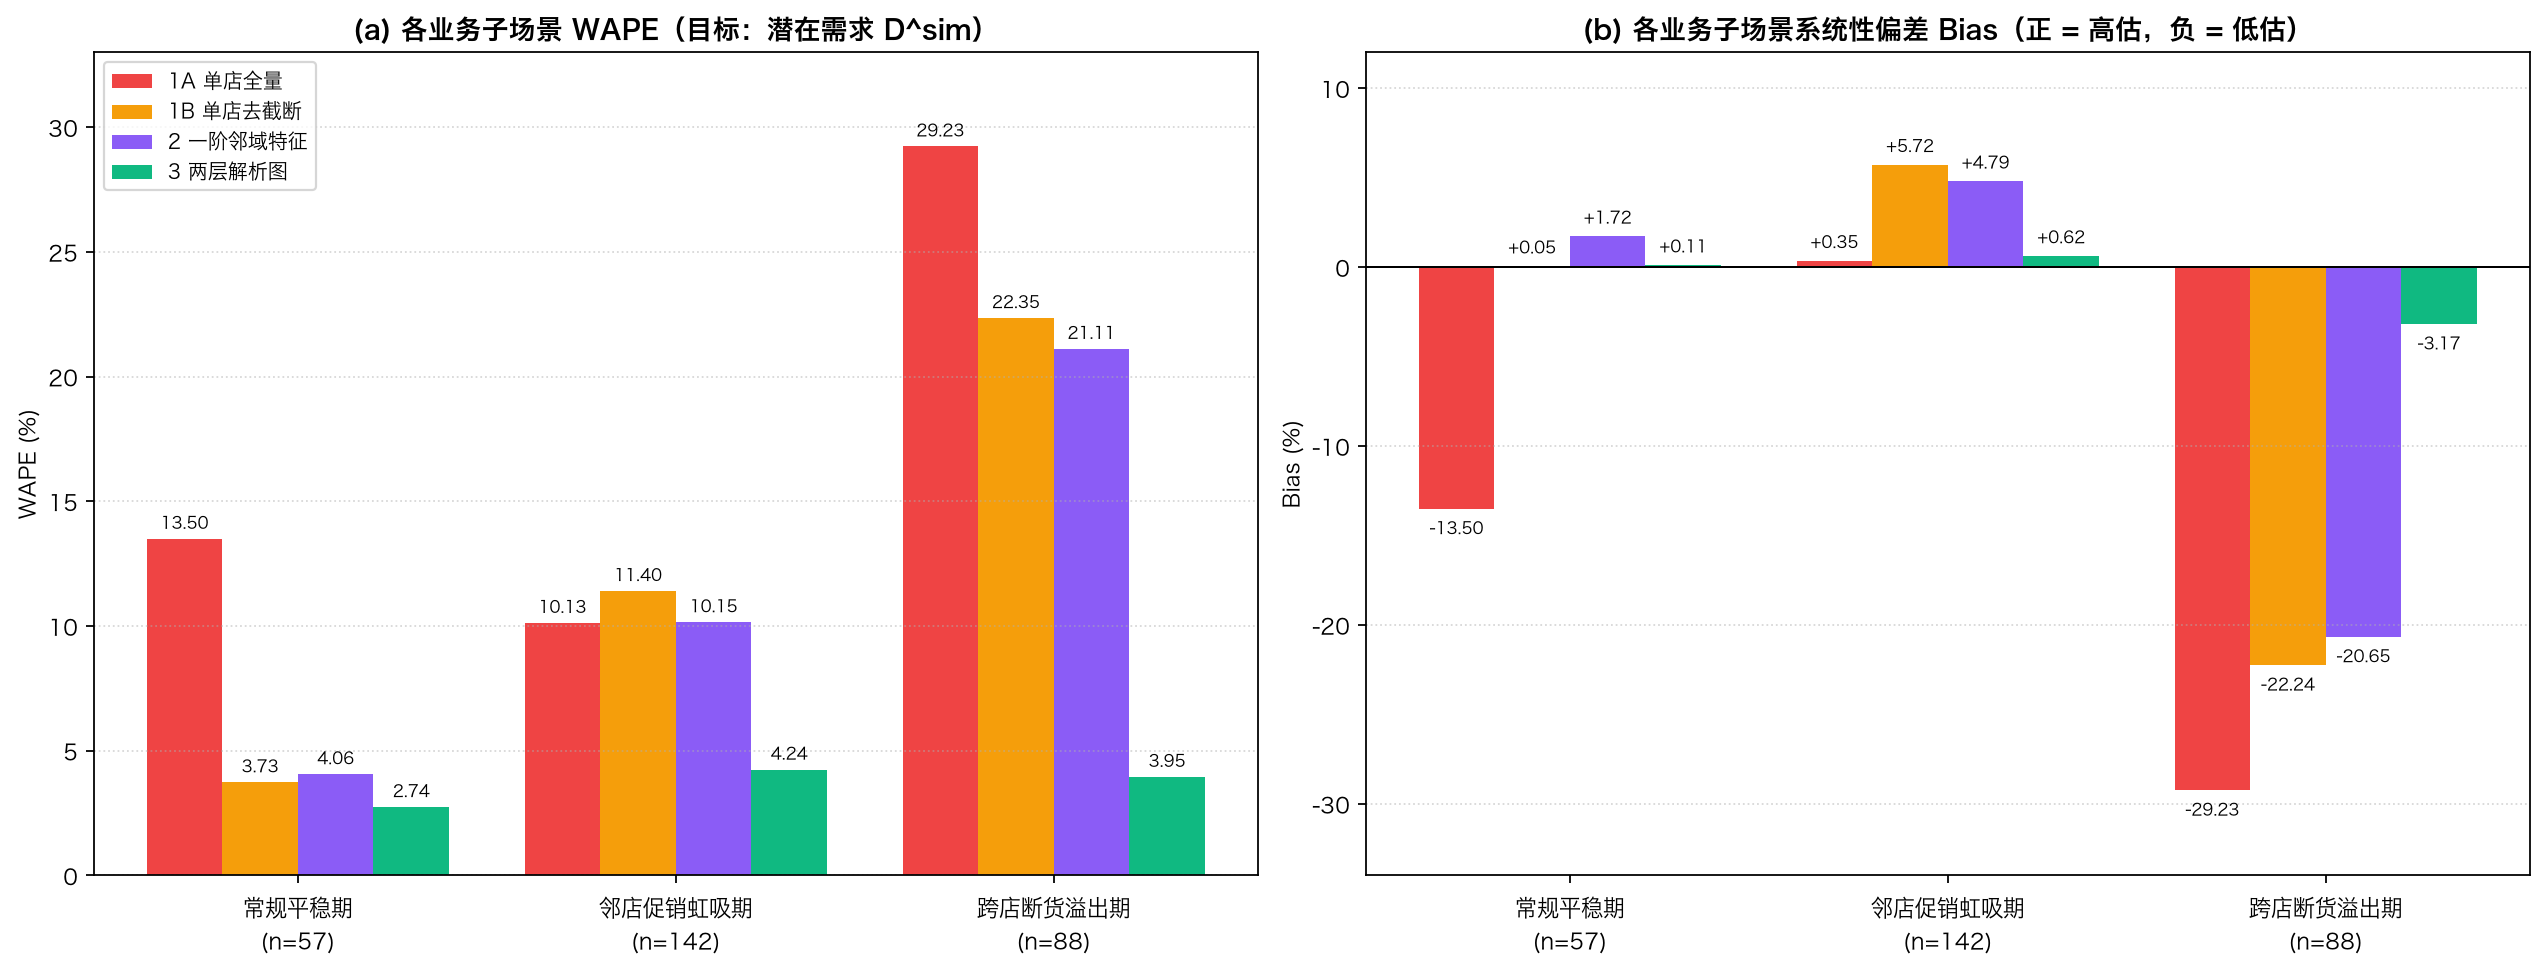

In [12]:
display(Markdown("**图 5：三大业务子场景（平稳期、虹吸期、溢出期）误差与系统性偏差消融对比**"))
display(Image(os.path.join(FIG_DIR, "regime_ablation_metrics.png"), width=980))

**图 5 解读**：
- (a) WAPE 分布展示了溢出期内单店与一阶特征模型的断崖式失效；
- (b) Bias 直观揭示了“符号翻转”现象：促销对应正向高估，断货对应负向低估。

## 4.6 主流时序与图学习工具包全景横向评测

本节固定信息层级（1B 单店、2 一阶邻域、3 两跳图），横向评测六大主流工具包（Meta Prophet、Darts、PyG Temporal、LibCity 等）。

In [13]:
sc = metrics["scorecard"]
table3_df = pd.DataFrame({
    "层级与参评工具": sc["toolkit_zh"],
    "耗时": sc["time_sec"].map(lambda s: f"{s:.3f}s" if s < 1 else f"{s:.1f}s"),
    "全量 / 平稳 WAPE": [f"{a:.2f}% / {b:.2f}%" for a, b in zip(sc["overall_wmape"], sc["normal_wmape"])],
    "虹吸 WAPE (Bias)": [f"{a:.2f}% ({b:+.1f}%)" for a, b in zip(sc["cannib_wmape"], sc["cannib_bias"])],
    "溢出 WAPE (Bias)": [f"{a:.2f}% ({b:+.1f}%)" for a, b in zip(sc["spillover_wmape"], sc["spillover_bias"])],
})
display(Markdown("**表 3：主流工具包全景评分卡（目标：潜在需求 $D^{\mathrm{sim}}$）**"))
display(table3_df)

**表 3：主流工具包全景评分卡（目标：潜在需求 $D^{\mathrm{sim}}$）**

,层级与参评工具,耗时,全量 / 平稳 WAPE,虹吸 WAPE (Bias),溢出 WAPE (Bias)
0,1B · Formula OLS,0.005s,13.78% / 3.73%,11.40% (+5.7%),22.35% (-22.2%)
1,1B · Meta Prophet,25.4s,13.98% / 3.84%,11.73% (+5.6%),22.43% (-22.4%)
2,1B · Darts,12.1s,13.78% / 3.73%,11.40% (+5.7%),22.35% (-22.2%)
3,2 · 1-Hop Flat OLS,0.010s,12.75% / 4.06%,10.15% (+4.8%),21.11% (-20.7%)
4,2 · Prophet add_regressor,38.6s,12.89% / 4.09%,10.48% (+4.9%),21.08% (-20.7%)
5,3 · ST-GNN 解析解,0.015s,3.79% / 2.74%,4.24% (+0.6%),3.95% (-3.2%)
6,3 · PyG Temporal,4.8s,3.82% / 2.74%,4.24% (+0.6%),3.98% (-3.2%)
7,3 · LibCity,18.5s,3.80% / 2.74%,4.24% (+0.6%),3.96% (-3.2%)


**表 3 关键发现（与博文 4.6 节评分卡严格一致）**：
1. **调包救不了信息盲区**：在 1B 单店层级内，无论选用 Formula OLS（0.005s）、Meta Prophet（25.4s）还是 Darts（12.1s），全量 WAPE 均卡死在 **13.78%–13.98%**；在溢出期内均在 **22.35%–22.43%**。
2. **两跳图结构实现代际跨越**：解析图模型（0.015s）、PyG Temporal（4.8s）与 LibCity（18.5s）全量 WAPE 均锁定在 **3.79%–3.82%**，溢出期降至 **3.95%–3.98%**。

**图 6：主流时序与图学习工具的运行耗时、断货溢出期 WAPE 及四层工具生态**

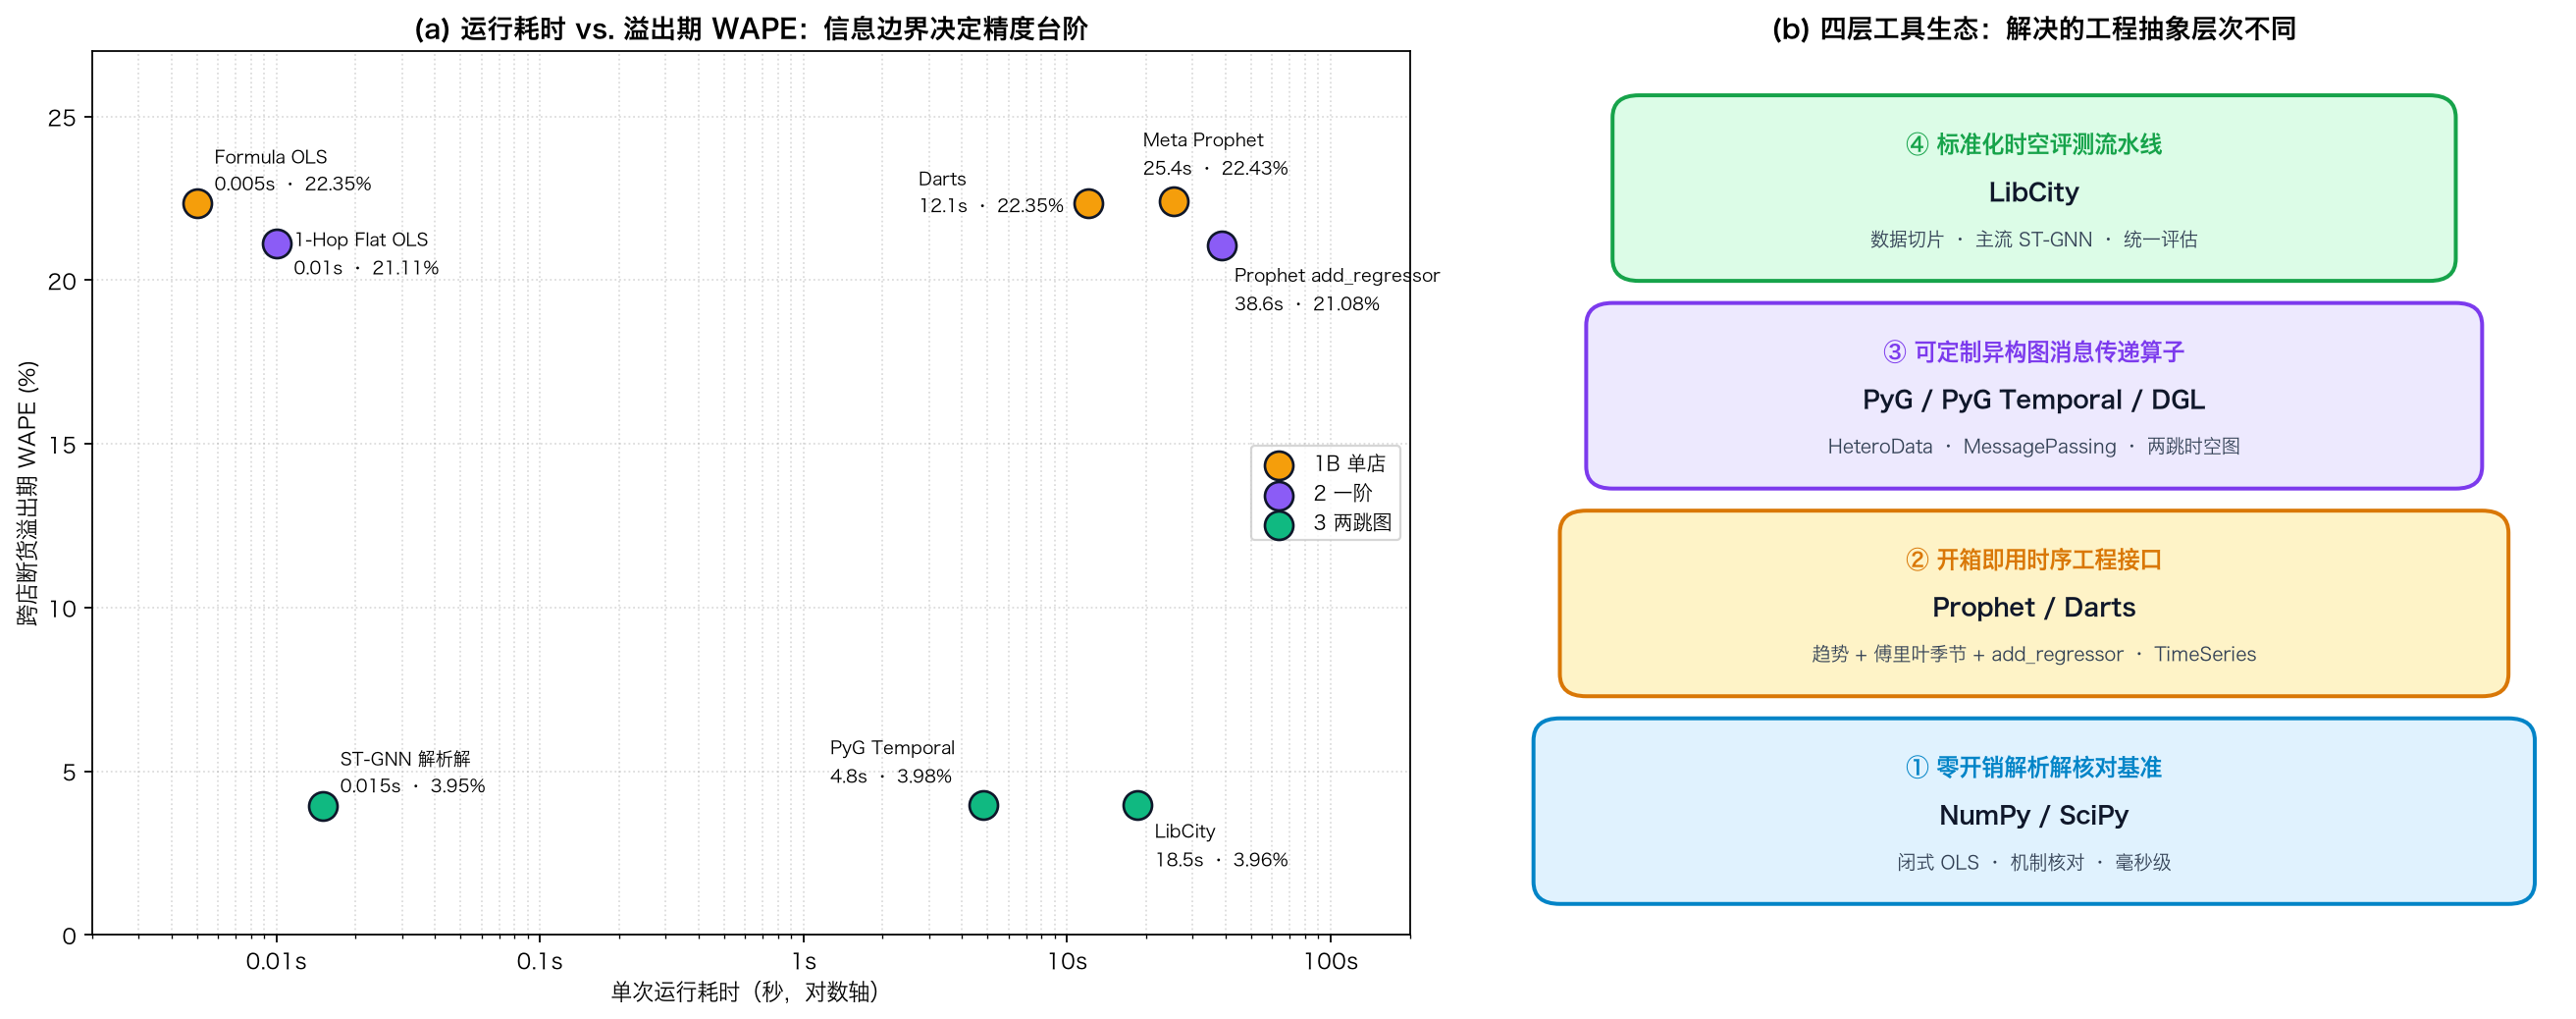

In [14]:
display(Markdown("**图 6：主流时序与图学习工具的运行耗时、断货溢出期 WAPE 及四层工具生态**"))
display(Image(os.path.join(FIG_DIR, "multitool_benchmark_tradeoff.png"), width=980))

**图 6 解读**：
- (a) 运行耗时从 0.005 秒到 38.6 秒跨越近 4 个数量级，同一信息层级内部工具间精度相近，代际差异源于特征边界。
- (b) 工具生态四层抽象：NumPy 闭式验证基准 $\to$ Prophet/Darts 时序工程抽象 $\to$ PyG/DGL 消息传递定制 $\to$ LibCity 统一评测管线。

## 数据文件复现性验证：重新加载 CSV

In [15]:
csv_reloaded = pd.read_csv(CSV_PATH)
D_from_csv = csv_reloaded.pivot(index="ds", columns="store_id", values="latent_demand")[sim["store_ids"]].to_numpy()

w_re, mae_re, b_re = calc_metrics(D_from_csv, ablation["pred_1b"], metrics["masks"]["Overall"])
print(f"Reloaded CSV Model 1B Metrics -> WAPE: {w_re:.2f}%, MAE: {mae_re:.2f}, Bias: {b_re:+.2f}%")
assert f"{w_re:.2f}|{mae_re:.2f}|{b_re:+.2f}" == "13.78|15.59|-5.63", "Reproduction mismatch!"
print("Exact 0.00% reproduction from CSV verified successfully!")

Reloaded CSV Model 1B Metrics -> WAPE: 13.78%, MAE: 15.59, Bias: -5.63%
Exact 0.00% reproduction from CSV verified successfully!


**验证结论**：直接从落盘的 `retail_network_2023_2025.csv` 文件重构潜在需求真值矩阵，模型 1B 的各项指标与内存计算结果完全一致，表明公开数据集具备完全的独立可复现性。

## 总结与工程反思

1. **信息边界是精度上限的决定性因素**：在未引入多跳拓扑信息时，复杂的单店调参无法突破物理信息盲区。
2. **业务场景决定模型选择**：孤立平稳的常规场景下单店模型性价比最高；而在强网络负外部性（促销虹吸）与正外部性（断货溢出）场景下，GNN 架构才能发挥显著优势。
3. **真实落地边界**：本受控实验验证了图结构在理论闭环下的拟合能力。在实际生产落地中，特征时效、图维护成本及故障爆炸半径等工程挑战更为关键（详见博文第五章）。